# Where Does the Regime Reversal Happen?

We saw low_vol has better coverage at day 0, but high_vol has better coverage
by day 29. Instead of just checking a few days, let's check every day from
0 to 29 and plot the gap. This shows exactly where the crossover happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
sensex_forecasts = np.load("../data/forecasts.npy")
sensex_actuals = np.load("../data/actuals.npy")
sensex_regimes = np.load("../data/sensex_regime_labels.npy", allow_pickle=True)

nifty_forecasts = np.load("../data/nifty_forecasts.npy")
nifty_actuals = np.load("../data/nifty_actuals.npy")
nifty_regimes = np.load("../data/nifty_regime_labels.npy", allow_pickle=True)

In [16]:
def coverage_gap_curve(forecasts, actuals, regimes, horizon=30):
    gaps = []
    for day in range(horizon):
        day_forecasts = forecasts[:, day, :]
        day_actuals = actuals[:, day]

        lower = day_forecasts[:, 1]
        upper = day_forecasts[:, 9]
        inside = (day_actuals >= lower) & (day_actuals <= upper)

        low_cov = inside[regimes == "low_vol"].mean()
        high_cov = inside[regimes == "high_vol"].mean()

        gaps.append(low_cov - high_cov)

    return np.array(gaps)

In [17]:
sensex_gaps = coverage_gap_curve(sensex_forecasts, sensex_actuals, sensex_regimes)
nifty_gaps = coverage_gap_curve(nifty_forecasts, nifty_actuals, nifty_regimes)

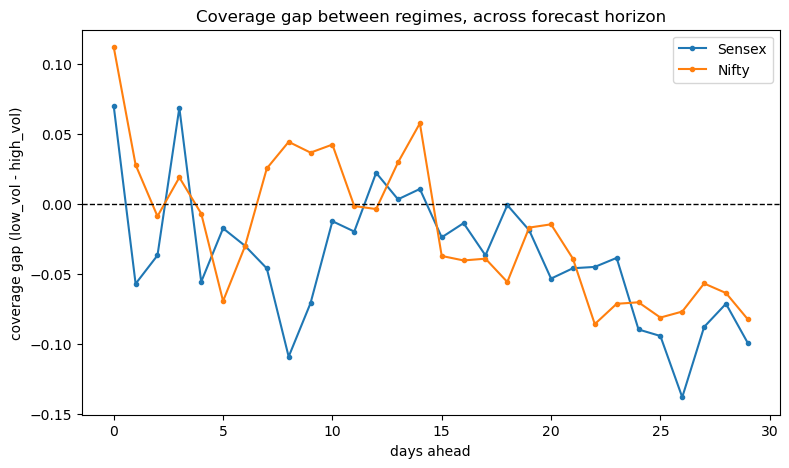

In [18]:
plt.figure(figsize=(9, 5))
plt.plot(sensex_gaps, label="Sensex", marker="o", markersize=3)
plt.plot(nifty_gaps, label="Nifty", marker="o", markersize=3)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("days ahead")
plt.ylabel("coverage gap (low_vol - high_vol)")
plt.title("Coverage gap between regimes, across forecast horizon")
plt.legend()
plt.show()

## Find the approximate crossover point

Where does the gap cross from positive (low_vol better) to negative
(high_vol better)?

In [19]:
def find_crossover(gaps):
    for day in range(1, len(gaps)):
        if gaps[day-1] > 0 and gaps[day] <= 0:
            return day
    return None

print("Sensex crossover around day:", find_crossover(sensex_gaps))
print("Nifty crossover around day:", find_crossover(nifty_gaps))

Sensex crossover around day: 1
Nifty crossover around day: 2


## Smoothed version

The raw curve is noisy day to day. A 3-day rolling average makes the
underlying trend easier to see without changing the actual data.

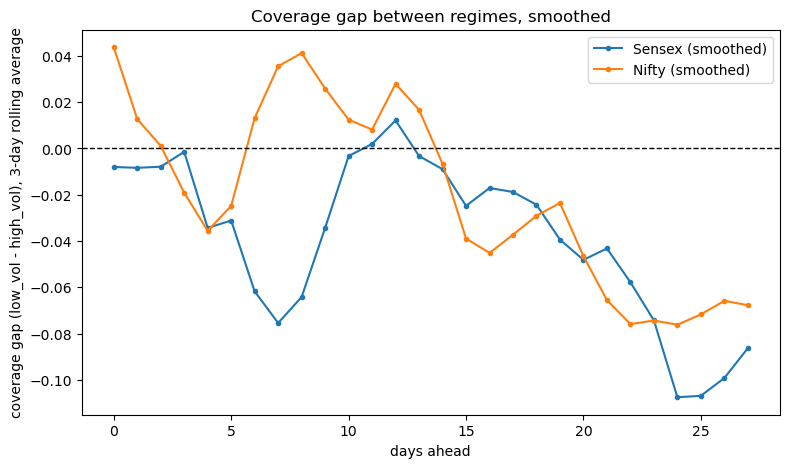

In [20]:
def smooth(x, window=3):
    return np.convolve(x, np.ones(window)/window, mode="valid")

sensex_smooth = smooth(sensex_gaps)
nifty_smooth = smooth(nifty_gaps)

plt.figure(figsize=(9, 5))
plt.plot(sensex_smooth, label="Sensex (smoothed)", marker="o", markersize=3)
plt.plot(nifty_smooth, label="Nifty (smoothed)", marker="o", markersize=3)
plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.xlabel("days ahead")
plt.ylabel("coverage gap (low_vol - high_vol), 3-day rolling average")
plt.title("Coverage gap between regimes, smoothed")
plt.legend()
plt.show()

## Three-region summary

Looking at both the raw and smoothed curves:

- Days 0-1: low_vol has a clear advantage (positive gap)
- Days 2-18: gap oscillates around zero, no reliable advantage either way
- Days 19-29: gap is consistently negative and grows larger, high_vol has
  a clear and strengthening advantage

This is a more accurate description than a single "crossover day", since
the middle of the horizon is genuinely noisy rather than a clean switch.

## Do Sensex and Nifty move together?

The smoothed plot looks like both curves follow a similar shape throughout
the horizon, not just at the start and end. Let's check this with a simple
correlation number instead of just eyeballing it.

In [21]:
correlation = np.corrcoef(sensex_gaps, nifty_gaps)[0, 1]
print("correlation between Sensex and Nifty coverage gap curves:", round(correlation, 3))

correlation between Sensex and Nifty coverage gap curves: 0.515


A correlation close to 1 means the two curves rise and fall together closely.
A correlation close to 0 would mean they are unrelated, which would suggest
the earlier pattern might just be noise in each series separately.

Since Sensex and Nifty both track the broader Indian stock market, a high
correlation here would make sense and would support the idea that this
reflects a real shared market dynamic, not independent randomness.

**Correlation check:** to test whether the shared appearance of the two
coverage-gap curves reflects a real common pattern or is an artifact of
visual smoothing, we computed the Pearson correlation between the raw
(unsmoothed) Sensex and Nifty gap curves across the 30-day horizon. The
result (r = 0.515) indicates a moderate positive relationship: the two
indices show a partially shared calibration pattern across the forecast
horizon, consistent with both tracking the same underlying Indian equity
market, but each also retains index-specific variation not explained by
the other. This supports treating the late-horizon reversal (days ~19-29)
as a genuine, non-coincidental pattern, while cautioning against over-
interpreting the closely-aligned appearance of the smoothed curves alone.